# Hogares de 30 a 44 años que viven en una vivienda en propiedad

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "hogares-30-44-propiedad"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Hogares de 30 a 44 años que viven en una vivienda en propiedad"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de los hogares de 30 a 44 años"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
MUESTRA_MINIMA = 50  # vista por comunidades: hogares de 30 a 44 años en la muestra para dar el dato
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Qué parte de los hogares cuya persona de referencia tiene entre 30 y 44 años vive en una vivienda de su propiedad, con o sin hipoteca, según la Encuesta de Condiciones de Vida del INE.

**Cómo se lee.** Un valor de 60 significa que seis de cada diez hogares de esa edad son propietarios de su vivienda; el resto vive de alquiler o en una vivienda cedida. Como solo cuenta a quienes ya han formado su propio hogar, depende menos que la edad de emancipación de costumbres familiares, y sirve para ver quién se queda fuera de la compra.

**Limitaciones.**
- Es una encuesta: los datos tienen margen de error muestral.
- Solo España: Eurostat no publica el régimen de tenencia según la edad de la persona de referencia del hogar.

**Vista por comunidades.** El INE no publica esta tabla por comunidad autónoma. El selector «Por comunidad» de la web la calcula con los microdatos de la misma encuesta y la misma definición que la tabla del INE (la persona de referencia es la primera responsable de la vivienda y su edad es la que cumple el año al que se refiere la renta); el total de España de ese cálculo coincide con la tabla. Si una comunidad tiene menos de 50 hogares de 30 a 44 años en la encuesta de un año, su dato de ese año no se muestra. Los microdatos empiezan en 2008.

## 2. Descarga

INE, Encuesta de Condiciones de Vida, tabla 9994 (hogares por régimen de tenencia y edad de la persona de referencia), serie `ECV2500` (30 a 44 años, propiedad), anual.

**Vista por comunidades:** INE, Encuesta de Condiciones de Vida, ficheros de microdatos transversales (base 2013), un zip por año desde 2008. No se guardan en el repositorio: se descargan al ejecutar el notebook (unos 500 MB en total).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, construir_vista_ccaa, write_grafica_data

from datetime import date

from lib import ecv, ine
from lib.ccaa import NOMBRES_CCAA
from lib.tipos import FuenteMeta


def descargar():
    """Devuelve (DataFrame `serie, periodo, valor`, lista de FuenteMeta)."""
    return ine.get({"ECV2500": "espana"}, desde=DESDE)


def descargar_ccaa():
    """Hogares de 30 a 44 años en propiedad por comunidad, un año tras otro, calculados con los microdatos de la
    ECV (`lib/ecv.py`). Se para en el primer año que el INE aún no ha publicado."""
    filas, fuente = [], None
    for anio in range(ecv.PRIMER_ANIO, date.today().year + 1):
        try:
            ficheros, fuente_anio = ecv.get(anio)
        except ecv.EcvError:
            if anio < date.today().year - 1:
                raise  # un año que ya debería estar publicado
            break
        fuente = fuente or fuente_anio
        filas.append(ecv.propiedad_por_edad(ficheros, 30, 44).reset_index().assign(periodo=anio))
    return pd.concat(filas, ignore_index=True), fuente


df, fuentes = descargar()
ccaa, fuente_ecv = descargar_ccaa()

## 3. Transformación

Los datos ya vienen en la unidad final.

In [ ]:
NOTAS = [
    "INE, Encuesta de Condiciones de Vida (tabla 9994): porcentaje de hogares cuya persona de referencia tiene entre 30 y 44 años que viven en una vivienda en propiedad, con o sin hipoteca.",
    "Es una encuesta: los datos tienen margen de error muestral.",
    "Solo España: Eurostat no publica el régimen de tenencia según la edad de la persona de referencia del hogar.",
]

# Vista por comunidades. Comprobación: el total de España del cálculo frente a la tabla 9994 del INE
contraste = pd.DataFrame({
    "cálculo microdatos": ccaa[ccaa.serie == "espana"].set_index("periodo")["tasa"],
    "INE tabla 9994": df.set_index("periodo")["valor"],
}).dropna()
contraste["diferencia"] = contraste["cálculo microdatos"] - contraste["INE tabla 9994"]
display(contraste.round(2))
DIF_MAX = contraste["diferencia"].abs().max()
assert DIF_MAX < 0.5, f"el cálculo con los microdatos se aleja de la tabla del INE ({DIF_MAX:.1f} puntos): ¿ha cambiado algún fichero?"

# Sin dato si la muestra es pequeña
pocos = ccaa[(ccaa.serie != "espana") & (ccaa.hogares < MUESTRA_MINIMA)]
df_ccaa = ccaa.assign(valor=ccaa["tasa"].where((ccaa.serie == "espana") | (ccaa.hogares >= MUESTRA_MINIMA)))
con_dato = set(df_ccaa.loc[df_ccaa.valor.notna(), "serie"])
df_ccaa = df_ccaa[df_ccaa.serie.isin(con_dato)][["serie", "periodo", "valor"]]
display(ccaa.pivot(index="periodo", columns="serie", values="hogares"))


def tramos(años: list[int]) -> str:
    """«2008-2013, 2015 y 2018»: años seguidos agrupados en intervalos."""
    grupos: list[list[int]] = []
    for a in sorted(años):
        if grupos and a == grupos[-1][-1] + 1:
            grupos[-1].append(a)
        else:
            grupos.append([a])
    partes = [f"{g[0]}-{g[-1]}" if len(g) > 1 else str(g[0]) for g in grupos]
    return partes[0] if len(partes) == 1 else f"{', '.join(partes[:-1])} y {partes[-1]}"


ANIOS = sorted(ccaa.periodo.unique())
fuera = [
    f"{NOMBRES_CCAA[s]} ({'todos los años' if len(g) == len(ANIOS) else tramos(g.periodo.tolist())})"
    for s, g in sorted(pocos.groupby("serie"), key=lambda x: NOMBRES_CCAA[x[0]])
]
fuentes_ccaa = [
    FuenteMeta(s, ecv.ORGANISMO,
               f"Encuesta de Condiciones de Vida, microdatos {ANIOS[0]}-{ANIOS[-1]} (base 2013): cálculo propio con la definición de la tabla 9994",
               ecv.URL_MICRODATOS, fuente_ecv.fecha_consulta)
    for s in sorted(con_dato)
]
NOTAS_CCAA = [
    "Cálculo propio con los microdatos de la Encuesta de Condiciones de Vida del INE y la definición de su tabla 9994: hogares cuya persona de referencia (la primera responsable de la vivienda) tiene entre 30 y 44 años en el año al que se refiere la renta, que viven en una vivienda en propiedad, con o sin hipoteca; ponderados con el peso transversal de los hogares. El INE no publica esta tabla por comunidad autónoma.",
    f"España es el total del mismo cálculo; difiere de la tabla 9994 del INE de la vista España en {f'{DIF_MAX:.1f}'.replace('.', ',')} puntos como máximo entre {contraste.index.min()} y {contraste.index.max()}.",
    f"Es una encuesta: el dato de una comunidad no se muestra los años en que tiene menos de {MUESTRA_MINIMA} hogares de 30 a 44 años en la muestra"
    + (f": {'; '.join(fuera)}." if fuera else "."),
    f"Los microdatos empiezan en {ANIOS[0]}, el primer año con la metodología de renta actual de la encuesta (base 2013).",
]
vista_ccaa = construir_vista_ccaa(df_ccaa, fuentes_ccaa, unidad=UNIDAD, notas=NOTAS_CCAA, desde=DESDE)
for n in NOTAS_CCAA:
    print("-", n)

,cálculo microdatos,INE tabla 9994,diferencia
periodo,,,
2008,73.66,73.7,-0.04
2009,73.74,73.8,-0.06
2010,73.73,73.7,0.03
2011,72.77,72.8,-0.03
2012,71.17,71.1,0.07
2013,67.87,67.9,-0.03
2014,68.62,68.6,0.02
2015,65.29,65.3,-0.01
2016,64.38,64.4,-0.02


serie,ES-AN,ES-AR,ES-AS,ES-CB,ES-CE,ES-CL,ES-CM,ES-CN,ES-CT,ES-EX,ES-GA,ES-IB,ES-MC,ES-MD,ES-ML,ES-NC,ES-PV,ES-RI,ES-VC,espana
periodo,,,,,,,,,,,,,,,,,,,,
2008,457,138,117,78,34,196,165,180,415,128,201,139,172,277,36,133,187,98,295,3446
2009,439,137,124,91,30,213,185,185,417,128,210,127,167,316,28,129,186,106,304,3522
2010,436,139,134,89,34,204,187,199,429,117,197,134,167,361,34,130,183,102,300,3576
2011,393,152,116,89,41,170,195,163,379,109,167,116,148,325,34,114,171,124,279,3285
2012,387,130,101,74,43,160,181,136,354,107,164,105,141,305,23,97,166,101,276,3051
2013,375,109,99,63,37,168,155,114,317,106,181,111,144,280,35,96,165,87,273,2915
2014,350,110,88,57,39,154,123,94,309,109,179,93,147,285,40,90,175,83,237,2762
2015,319,95,90,69,28,142,138,104,328,112,162,101,123,319,36,104,185,85,216,2756
2016,319,85,98,80,20,141,121,90,713,113,148,116,129,317,33,90,173,73,210,3069


- Cálculo propio con los microdatos de la Encuesta de Condiciones de Vida del INE y la definición de su tabla 9994: hogares cuya persona de referencia (la primera responsable de la vivienda) tiene entre 30 y 44 años en el año al que se refiere la renta, que viven en una vivienda en propiedad, con o sin hipoteca; ponderados con el peso transversal de los hogares. El INE no publica esta tabla por comunidad autónoma.
- España es el total del mismo cálculo; difiere de la tabla 9994 del INE de la vista España en 0,1 puntos como máximo entre 2008 y 2025.
- Es una encuesta: el dato de una comunidad no se muestra los años en que tiene menos de 50 hogares de 30 a 44 años en la muestra: Ceuta (2008-2019, 2021-2022 y 2025); Melilla (todos los años).
- Los microdatos empiezan en 2008, el primer año con la metodología de renta actual de la encuesta (base 2013).


## 4. Visualización

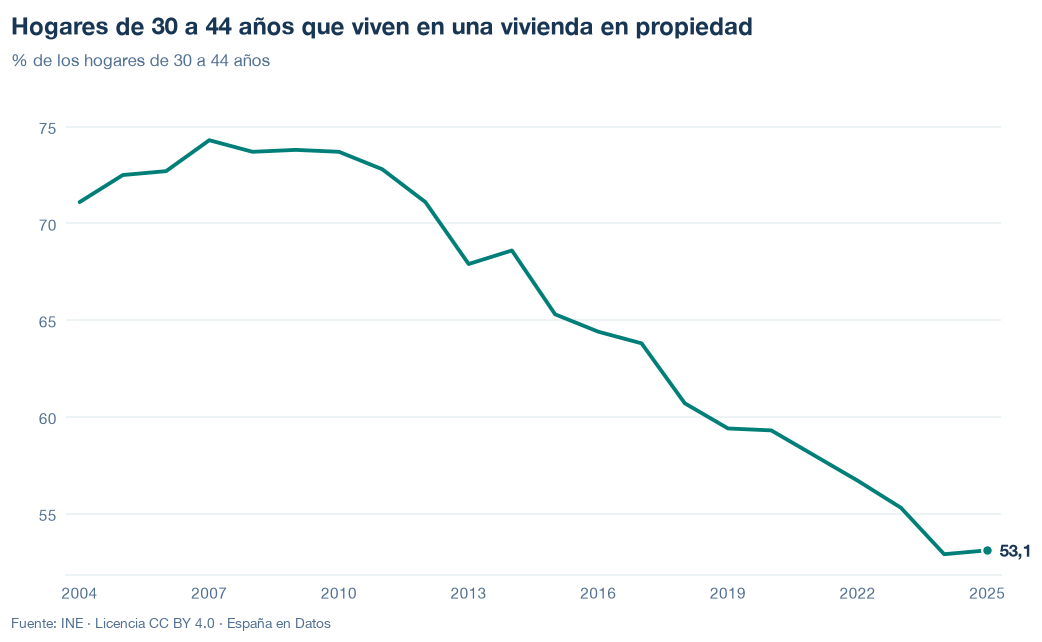

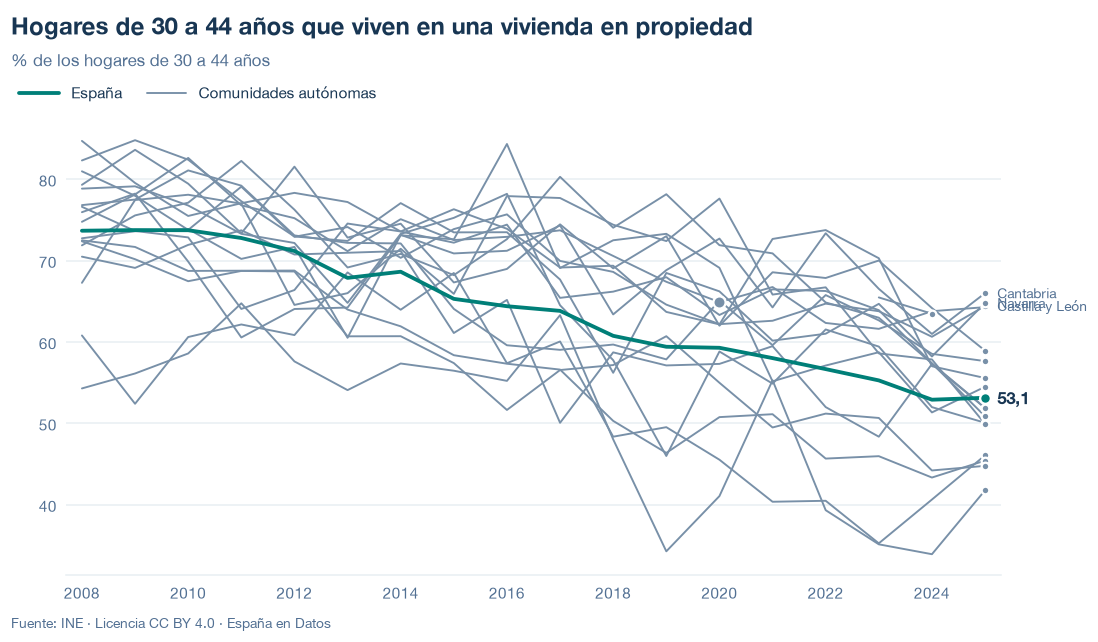

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, ccaa=vista_ccaa,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)
estilos.mostrar(estilos.figura_ccaa(datos, titulo=TITULO))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, ccaa=vista_ccaa,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/hogares-30-44-propiedad.json y data/hogares-30-44-propiedad.csv


## 6. Fuentes, notas y licencia

- INE, Encuesta de Condiciones de Vida, serie `ECV2500` (tabla 9994).
- Vista por comunidades: INE, Encuesta de Condiciones de Vida, ficheros de microdatos transversales (base 2013), cálculo propio con la definición de la tabla 9994.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.